<a href="https://colab.research.google.com/github/snehanagarajan-1452/Sokoban/blob/main/RBTHC_revision_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RB-THC revision experiments

**What it does**
1. Loads standard benchmarks: Boxoban (DeepMind) unfiltered / medium / hard tiers; optional XSB files (e.g. Microban).
2. Validates levels (box count == goal count, no box starting on a dead square).
3. Runs 7 solvers under an identical node + time budget and the same heuristic:
   HC, HC+restarts, Beam, Tabu, RB-THC (no restarts), RB-THC (full), GBFS (complete reference).
   HC / Beam / Tabu / RB-THC-noRR / RB-THC form the **ablation** (beam vs tabu vs restarts).
4. Seeds randomise tie-breaking (and restarts) so repeated runs are genuinely different.
5. Statistics: solve rate with level-bootstrap 95% CI, exact McNemar and Wilcoxon signed-rank
   (RB-THC vs each baseline, Holm-corrected), cost comparison on commonly solved levels.
6. Sensitivity sweep over beam width k and tabu tenure; failure analysis; runtime.
7. Writes CSVs + 300-dpi figures to `results/`.

In [1]:
# CELL 1: setup (Colab). Clones Boxoban levels once.
import os, subprocess, sys
if not os.path.exists('boxoban-levels'):
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/google-deepmind/boxoban-levels.git'], check=True)
os.makedirs('results', exist_ok=True)

In [2]:
# CELL 2: imports + global config
import collections, heapq, json, math, platform, random, time
from dataclasses import dataclass, field, asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import wilcoxon, binomtest

CFG = dict(
    tiers={                       # tier -> (file, n levels sampled)
        'unfiltered': ('boxoban-levels/unfiltered/test/000.txt', 100),
        'medium':     ('boxoban-levels/medium/valid/000.txt', 100),
        'hard':       ('boxoban-levels/hard/000.txt', 100),
    },
    level_sample_seed=0,
    seeds=[0, 1, 2, 3, 4],        # per stochastic solver; every solver runs all seeds
    max_expansions=3000,          # node budget per run (identical for all solvers)
    time_limit=10.0,              # seconds per run (safety cap)
    heuristic='matching',         # 'matching' (Hungarian on push distance) or 'nearest' (paper Eq. 2 style)
    beam_width=4,
    tabu_size=500,
    patience=50,                  # RB-THC: restart after this many iters without best-h improvement
    walk_len=3,                   # random pushes from start state on restart
    n_workers=os.cpu_count(),
)
json.dump(CFG, open('results/config.json', 'w'), indent=2)
print(json.dumps(CFG, indent=1)); print('python', platform.python_version(), '| workers', CFG['n_workers'])

{
 "tiers": {
  "unfiltered": [
   "boxoban-levels/unfiltered/test/000.txt",
   100
  ],
  "medium": [
   "boxoban-levels/medium/valid/000.txt",
   100
  ],
  "hard": [
   "boxoban-levels/hard/000.txt",
   100
  ]
 },
 "level_sample_seed": 0,
 "seeds": [
  0,
  1,
  2,
  3,
  4
 ],
 "max_expansions": 3000,
 "time_limit": 10.0,
 "heuristic": "matching",
 "beam_width": 4,
 "tabu_size": 500,
 "patience": 50,
 "walk_len": 3,
 "n_workers": 2
}
python 3.13.16 | workers 2


In [3]:
# CELL 3: level loading + static analysis (dead squares, push distances)
@dataclass
class Level:
    name: str
    W: int
    H: int
    walls: frozenset
    floor: frozenset       # cells reachable by player ignoring boxes
    goals: tuple
    boxes0: tuple
    player0: int
    dirs: tuple = ()
    dead: frozenset = frozenset()
    gdist: np.ndarray = None   # (n_goals, W*H) push distance box->goal, ignoring other boxes

def parse_xsb(lines, name):
    rows = [l.rstrip('\n') for l in lines if l.strip()]
    H = len(rows); W = max(len(r) for r in rows)
    rows = [r.ljust(W) for r in rows]
    walls, goals, boxes = set(), set(), set(); player = None
    for r, row in enumerate(rows):
        for c, ch in enumerate(row):
            i = r * W + c
            if ch == '#': walls.add(i)
            if ch in '.*+': goals.add(i)
            if ch in '$*': boxes.add(i)
            if ch in '@+': player = i
    return build_level(name, W, H, walls, goals, boxes, player)

def build_level(name, W, H, walls, goals, boxes, player):
    dirs = (-W, W, -1, 1)
    # floor = player-reachable ignoring boxes (outside-of-level spaces excluded)
    floor = {player}; q = collections.deque([player])
    while q:
        p = q.popleft()
        for d in dirs:
            n = p + d
            if 0 <= n < W * H and n not in walls and n not in floor and abs((n % W) - (p % W)) <= 1:
                floor.add(n); q.append(n)
    goals_t = tuple(sorted(goals))
    # reverse "pull" BFS from each goal -> push distance; cells with inf to every goal are dead
    gdist = np.full((len(goals_t), W * H), np.inf)
    for gi, g in enumerate(goals_t):
        gdist[gi, g] = 0; q = collections.deque([g])
        while q:
            b = q.popleft()
            for d in dirs:
                prev = b - d; ply = prev - d        # box was at prev, player at prev-d, pushed by +d
                if prev in floor and ply in floor and gdist[gi, prev] == np.inf:
                    gdist[gi, prev] = gdist[gi, b] + 1; q.append(prev)
    dead = frozenset(c for c in floor if np.all(np.isinf(gdist[:, c])))
    return Level(name, W, H, frozenset(walls), frozenset(floor), goals_t, tuple(sorted(boxes)),
                 player, dirs, dead, gdist)

def validate(lv):
    if len(lv.boxes0) != len(lv.goals): return 'box/goal count mismatch'
    if any(b in lv.dead and b not in lv.goals for b in lv.boxes0): return 'box starts on dead square'
    if any(b not in lv.floor for b in lv.boxes0): return 'box outside floor'
    return None

def load_file(path, prefix):
    levels, buf, name = [], [], None
    for line in open(path):
        if line.startswith(';'):
            if buf: levels.append(parse_xsb(buf, name))
            name = f"{prefix}:{line[1:].strip()}"; buf = []
        elif line.strip(): buf.append(line)
    if buf: levels.append(parse_xsb(buf, name))
    return levels

LEVELS = {}
for tier, (path, n) in CFG['tiers'].items():
    allv = load_file(path, tier)
    rng = random.Random(CFG['level_sample_seed'])
    chosen = rng.sample(allv, min(n, len(allv)))
    bad = [(lv.name, validate(lv)) for lv in chosen if validate(lv)]
    if bad: print('INVALID levels dropped:', bad)
    LEVELS[tier] = [lv for lv in chosen if not validate(lv)]
    print(f"{tier:10s} {len(LEVELS[tier])} levels from {path}")
# To add Microban (or any XSB/.sok file): LEVELS['microban'] = load_file('Microban.txt', 'microban')

unfiltered 100 levels from boxoban-levels/unfiltered/test/000.txt
medium     100 levels from boxoban-levels/medium/valid/000.txt
hard       100 levels from boxoban-levels/hard/000.txt


In [4]:
# CELL 4: state space, heuristic, successor generation
# A state is (canonical_player, boxes) where canonical_player = min player-reachable cell,
# so states differing only in player position within the same region are identical (tabu/dedupe).

def reach(lv, player, boxes_set):
    seen = {player}; q = collections.deque([player])
    while q:
        p = q.popleft()
        for d in lv.dirs:
            n = p + d
            if n in lv.floor and n not in boxes_set and n not in seen:
                seen.add(n); q.append(n)
    return seen

def canon(lv, player, boxes):
    return (min(reach(lv, player, set(boxes))), boxes)

def is_goal(lv, state):
    return state[1] == lv.goals

def heuristic(lv, boxes, kind):
    if kind == 'matching':      # min-cost box->goal assignment on true push distances (admissible)
        cost = lv.gdist[:, list(boxes)].T
        cost = np.where(np.isinf(cost), 1e6, cost)
        r, c = linear_sum_assignment(cost)
        return float(cost[r, c].sum())
    # 'nearest': paper Eq. 2 — sum of nearest-goal Manhattan distances
    W = lv.W
    return float(sum(min(abs(b // W - g // W) + abs(b % W - g % W) for g in lv.goals) for b in boxes))

class Counter:
    def __init__(self, budget, tlimit):
        self.exp = 0; self.gen = 0; self.mem = 1; self.budget = budget; self.t0 = time.perf_counter(); self.tl = tlimit
    def out(self):
        return self.exp >= self.budget or time.perf_counter() - self.t0 > self.tl

def successors(lv, state, ctr):
    """All legal pushes; pushes onto dead squares are pruned (same for every solver)."""
    ctr.exp += 1
    player, boxes = state; bset = set(boxes)
    r = reach(lv, player, bset); out = []
    for b in boxes:
        for d in lv.dirs:
            dest = b + d
            if (b - d) in r and dest in lv.floor and dest not in bset and dest not in lv.dead:
                nb = tuple(sorted((bset - {b}) | {dest}))
                out.append(canon(lv, b, nb)); ctr.gen += 1
    return out

def path_len(node):
    n = 0
    while node[1] is not None: node = node[1]; n += 1
    return n

def path_states(node):
    s = []
    while node is not None: s.append(node[0]); node = node[1]
    return s[::-1]

def verify(lv, states):
    """Independent check: consecutive states differ by one legal push and last is solved."""
    dummy = Counter(10**12, 1e9)
    for a, b in zip(states, states[1:]):
        if b not in successors(lv, a, dummy): return False
    return is_goal(lv, states[-1])

In [5]:
# CELL 5: solvers. Every solver returns a dict; nodes are (state, parent_node) linked lists.

def _result(lv, solved, best_node, best_h, ctr, reason, trace):
    states = path_states(best_node) if best_node else []
    ok = verify(lv, states) if solved else False
    return dict(solved=bool(solved and ok), verified=ok if solved else None,
                pushes=path_len(best_node) if solved else np.nan,
                expansions=ctr.exp, generated=ctr.gen, peak_stored_states=ctr.mem,
                time=time.perf_counter() - ctr.t0, best_h=best_h,
                reason=reason, trace=trace + ([(ctr.exp, 0.0)] if solved else []))

def _rank(cands, rng):
    # sort by h, random tie-break (seeded) -> repeated runs genuinely differ
    return sorted(cands, key=lambda x: (x[0], rng.random()))

def _random_walk(lv, start, rng, n, ctr):
    node = (start, None)
    for _ in range(n):
        s = successors(lv, node[0], ctr)
        if not s: break
        node = (rng.choice(s), node)
    return node

def hill_climb(lv, rng, P, restarts=False):
    """Steepest-descent HC; stops at local optimum (plain) or restarts via random walk (HC-RR)."""
    ctr = Counter(P['max_expansions'], P['time_limit']); hk = P['heuristic']
    s0 = canon(lv, lv.player0, lv.boxes0)
    node = (s0, None); h = heuristic(lv, s0[1], hk)
    best_node, best_h, trace = node, h, []
    while not ctr.out():
        if is_goal(lv, node[0]): return _result(lv, True, node, 0.0, ctr, 'solved', trace)
        cands = _rank([(heuristic(lv, s[1], hk), s) for s in successors(lv, node[0], ctr)], rng)
        trace.append((ctr.exp, best_h))
        if cands and cands[0][0] < h:
            h, node = cands[0][0], (cands[0][1], node)
            if h < best_h: best_h, best_node = h, node
        elif restarts:
            node = _random_walk(lv, s0, rng, P['walk_len'], ctr); h = heuristic(lv, node[0][1], hk)
        else:
            return _result(lv, False, best_node, best_h, ctr, 'local_optimum', trace)
    return _result(lv, False, best_node, best_h, ctr, 'budget', trace)

def rb_thc(lv, rng, P, k, tabu_size, restarts):
    """Unified beam/tabu local search.
       k=1, tabu>0      -> plain Tabu search
       k>1, tabu=0      -> plain Beam search (no memory)
       k>1, tabu>0      -> RB-THC ; restarts=True adds stagnation-triggered random restarts."""
    ctr = Counter(P['max_expansions'], P['time_limit']); hk = P['heuristic']
    s0 = canon(lv, lv.player0, lv.boxes0)
    start = (s0, None)
    best_node, best_h, trace = start, heuristic(lv, s0[1], hk), []
    while True:
        beam = [(heuristic(lv, start[0][1], hk), start)]
        tabu = collections.deque(); tabu_set = set(); stall = 0
        while not ctr.out():
            for h, nd in beam:
                if is_goal(lv, nd[0]): return _result(lv, True, nd, 0.0, ctr, 'solved', trace)
            cands, seen = [], set()
            for h, nd in beam:
                if ctr.out(): break
                for s in successors(lv, nd[0], ctr):
                    if s in tabu_set or s in seen: continue
                    seen.add(s); cands.append((heuristic(lv, s[1], hk), (s, nd)))
            # tabu: add current beam states (FIFO, fixed tenure)
            if tabu_size:
                for h, nd in beam:
                    if nd[0] not in tabu_set:
                        tabu.append(nd[0]); tabu_set.add(nd[0])
                        if len(tabu) > tabu_size: tabu_set.discard(tabu.popleft())
            if not cands: break
            beam = _rank(cands, rng)[:k]
            ctr.mem = max(ctr.mem, len(tabu_set) + len(beam))
            if beam[0][0] < best_h: best_h, best_node, stall = beam[0][0], beam[0][1], 0
            else: stall += 1
            trace.append((ctr.exp, best_h))
            if restarts and stall >= P['patience']: break
        if ctr.out():
            return _result(lv, False, best_node, best_h, ctr, 'budget', trace)
        if not restarts:
            return _result(lv, False, best_node, best_h, ctr, 'no_candidates', trace)
        start = _random_walk(lv, s0, rng, P['walk_len'], ctr)

def gbfs(lv, rng, P):
    """Greedy best-first search with closed list: complete within budget (global-search reference)."""
    ctr = Counter(P['max_expansions'], P['time_limit']); hk = P['heuristic']
    s0 = canon(lv, lv.player0, lv.boxes0); h0 = heuristic(lv, s0[1], hk)
    openl = [(h0, rng.random(), (s0, None))]; closed = {s0}
    best_node, best_h, trace = (s0, None), h0, []
    while openl and not ctr.out():
        h, _, nd = heapq.heappop(openl)
        if is_goal(lv, nd[0]): return _result(lv, True, nd, 0.0, ctr, 'solved', trace)
        if h < best_h: best_h, best_node = h, nd
        for s in successors(lv, nd[0], ctr):
            if s not in closed:
                closed.add(s); heapq.heappush(openl, (heuristic(lv, s[1], hk), rng.random(), (s, nd)))
        ctr.mem = len(closed)
        trace.append((ctr.exp, best_h))
    return _result(lv, False, best_node, best_h, ctr, 'budget' if openl else 'exhausted', trace)

def make_solvers(P, k=None, tabu=None):
    k = k or P['beam_width']; tabu = P['tabu_size'] if tabu is None else tabu
    return {  # name -> (fn, stochastic?)
        'HC':          (lambda lv, rng: hill_climb(lv, rng, P, False), True),
        'HC-RR':       (lambda lv, rng: hill_climb(lv, rng, P, True), True),
        'Beam':        (lambda lv, rng: rb_thc(lv, rng, P, k, 0, False), True),
        'Tabu':        (lambda lv, rng: rb_thc(lv, rng, P, 1, tabu, False), True),
        'RB-THC-noRR': (lambda lv, rng: rb_thc(lv, rng, P, k, tabu, False), True),
        'RB-THC':      (lambda lv, rng: rb_thc(lv, rng, P, k, tabu, True), True),
        'GBFS':        (lambda lv, rng: gbfs(lv, rng, P), True),
    }

In [6]:
# CELL 6: parallel runner (fork-based; works on Colab/Linux)
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

_JOBS = None
def _run_one(i):
    tier, li, solver, seed, P, k, tabu = _JOBS[i]
    lv = LEVELS[tier][li]
    fn, _ = make_solvers(P, k, tabu)[solver]
    r = fn(lv, random.Random(seed * 1_000_003 + li))
    trace = r.pop('trace')
    r.update(tier=tier, level=lv.name, solver=solver, seed=seed, k=k, tabu=tabu,
             n_boxes=len(lv.goals))
    return r, (trace if seed == 0 else None)

def run_grid(jobs, workers):
    global _JOBS; _JOBS = jobs
    rows, traces = [], {}
    t0 = time.time()
    with ProcessPoolExecutor(workers, mp_context=mp.get_context('fork')) as ex:
        for n, (r, tr) in enumerate(ex.map(_run_one, range(len(jobs)), chunksize=8)):
            rows.append(r)
            if tr is not None: traces[(r['tier'], r['level'], r['solver'], r['k'], r['tabu'])] = tr
            if (n + 1) % 500 == 0: print(f"  {n+1}/{len(jobs)} runs, {time.time()-t0:.0f}s")
    return pd.DataFrame(rows), traces

In [7]:
# CELL 7: MAIN EXPERIMENT (all tiers x solvers x seeds)
P = dict(CFG)
jobs = [(t, li, s, sd, P, P['beam_width'], P['tabu_size'])
        for t in LEVELS for li in range(len(LEVELS[t]))
        for s in make_solvers(P) for sd in CFG['seeds']]
print(len(jobs), 'runs')
t0 = time.time()
df, TRACES = run_grid(jobs, CFG['n_workers'])
print(f"done in {time.time()-t0:.0f}s")
assert df.loc[df.solved, 'verified'].all(), 'unverified solution!'
df.to_csv('results/main_runs.csv', index=False)

10500 runs
  500/10500 runs, 10s
  1000/10500 runs, 39s
  1500/10500 runs, 65s
  2000/10500 runs, 76s
  2500/10500 runs, 83s
  3000/10500 runs, 91s
  3500/10500 runs, 101s
  4000/10500 runs, 138s
  4500/10500 runs, 185s
  5000/10500 runs, 223s
  5500/10500 runs, 264s
  6000/10500 runs, 305s
  6500/10500 runs, 335s
  7000/10500 runs, 366s
  7500/10500 runs, 415s
  8000/10500 runs, 451s
  8500/10500 runs, 499s
  9000/10500 runs, 543s
  9500/10500 runs, 594s
  10000/10500 runs, 640s
  10500/10500 runs, 688s
done in 688s


In [8]:
# CELL 8: Table — solve rate (level-bootstrap 95% CI), cost, time
ORDER = ['HC', 'HC-RR', 'Beam', 'Tabu', 'RB-THC-noRR', 'RB-THC', 'GBFS']

def boot_ci(per_level, B=2000, seed=0):
    rng = np.random.default_rng(seed); x = np.asarray(per_level)
    m = rng.choice(x, (B, len(x))).mean(1)
    return np.percentile(m, [2.5, 97.5])

rows = []
for (tier, solver), g in df.groupby(['tier', 'solver']):
    per_level = g.groupby('level').solved.mean()
    lo, hi = boot_ci(per_level.values)
    sol = g[g.solved]
    rows.append(dict(tier=tier, solver=solver, solve_rate=100 * g.solved.mean(),
                     ci_lo=100 * lo, ci_hi=100 * hi,
                     levels_ever_solved=int((per_level > 0).sum()), n_levels=len(per_level),
                     median_pushes=sol.pushes.median(), median_expansions=sol.expansions.median(),
                     mean_time_s=g.time.mean()))
T1 = pd.DataFrame(rows)
T1['solver'] = pd.Categorical(T1.solver, ORDER); T1 = T1.sort_values(['tier', 'solver'])
T1.to_csv('results/table_main.csv', index=False)
T1.round(2)

,tier,solver,solve_rate,ci_lo,ci_hi,levels_ever_solved,n_levels,median_pushes,median_expansions,mean_time_s
2,hard,HC,2.2,0.60,4.2,6,100,12.0,12.0,0.00
3,hard,HC-RR,22.0,14.40,29.8,27,100,14.5,253.5,0.46
0,hard,Beam,16.6,10.60,22.6,29,100,15.0,54.0,0.42
6,hard,Tabu,3.8,1.80,6.2,12,100,13.0,13.0,0.00
5,hard,RB-THC-noRR,20.4,13.80,27.0,38,100,15.5,54.0,0.02
4,hard,RB-THC,54.4,45.40,63.2,65,100,17.0,206.5,0.30
1,hard,GBFS,100.0,100.00,100.0,100,100,20.0,221.0,0.08
9,medium,HC,5.4,2.20,9.2,11,100,11.0,11.0,0.00
10,medium,HC-RR,43.0,33.80,52.0,48,100,15.0,239.0,0.40
7,medium,Beam,36.6,29.40,44.0,57,100,16.0,57.0,0.36


In [9]:
# CELL 9: Statistics — RB-THC vs each baseline, per tier
#   McNemar (exact, seed 0, paired per level on solved/unsolved)
#   Wilcoxon signed-rank on per-level solve rate across seeds
#   Holm correction within each tier
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for r, i in enumerate(o):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

stat_rows = []
for tier in LEVELS:
    d = df[df.tier == tier]
    rate = d.pivot_table(index='level', columns='solver', values='solved', aggfunc='mean')
    s0 = d[d.seed == 0].pivot_table(index='level', columns='solver', values='solved', aggfunc='first')
    block = []
    for base in [s for s in ORDER if s != 'RB-THC']:
        a, b = s0['RB-THC'].astype(bool), s0[base].astype(bool)
        n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
        p_mc = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
        diff = rate['RB-THC'] - rate[base]
        p_w = wilcoxon(diff, zero_method='zsplit').pvalue if (diff != 0).any() else 1.0
        block.append(dict(tier=tier, baseline=base, rbthc_only=n10, baseline_only=n01, p_mcnemar=p_mc,
                          mean_rate_diff_pct=100 * diff.mean(), p_wilcoxon=p_w))
    for key in ['p_mcnemar', 'p_wilcoxon']:
        adj = holm([r[key] for r in block])
        for r, a_ in zip(block, adj): r[key + '_holm'] = a_
    stat_rows += block
T2 = pd.DataFrame(stat_rows); T2.to_csv('results/table_stats.csv', index=False)
T2.round(4)

,tier,baseline,rbthc_only,baseline_only,p_mcnemar,mean_rate_diff_pct,p_wilcoxon,p_mcnemar_holm,p_wilcoxon_holm
0,unfiltered,HC,64,0,0.0000,62.2,0.0000,0.0000,0.0000
1,unfiltered,HC-RR,7,0,0.0156,7.6,0.0699,0.0312,0.1398
2,unfiltered,Beam,13,0,0.0002,14.4,0.0001,0.0010,0.0003
3,unfiltered,Tabu,38,0,0.0000,43.6,0.0000,0.0000,0.0000
4,unfiltered,RB-THC-noRR,10,0,0.0020,10.0,0.0014,0.0059,0.0043
5,unfiltered,GBFS,0,1,1.0000,-1.0,0.8438,1.0000,0.8438
6,medium,HC,70,0,0.0000,73.0,0.0000,0.0000,0.0000
7,medium,HC-RR,33,0,0.0000,35.4,0.0000,0.0000,0.0000
8,medium,Beam,39,0,0.0000,41.8,0.0000,0.0000,0.0000
9,medium,Tabu,67,0,0.0000,68.8,0.0000,0.0000,0.0000


In [10]:
# CELL 10: Cost on commonly solved levels (fair comparison of pushes / expansions)
cost_rows = []
for tier in LEVELS:
    d = df[(df.tier == tier) & (df.seed == 0)]
    for base in ['Beam', 'Tabu', 'RB-THC-noRR', 'HC-RR', 'GBFS']:
        pv = d[d.solver.isin(['RB-THC', base]) & d.solved].pivot_table(
            index='level', columns='solver', values=['pushes', 'expansions'])
        pv = pv.dropna()
        if len(pv) < 6: continue
        for m in ['pushes', 'expansions']:
            x, y = pv[(m, 'RB-THC')], pv[(m, base)]
            p = wilcoxon(x - y, zero_method='zsplit').pvalue if (x != y).any() else 1.0
            cost_rows.append(dict(tier=tier, baseline=base, metric=m, n_common=len(pv),
                                  rbthc_median=x.median(), baseline_median=y.median(), p_wilcoxon=p))
T3 = pd.DataFrame(cost_rows); T3.to_csv('results/table_cost_common.csv', index=False)
T3.round(4)

,tier,baseline,metric,n_common,rbthc_median,baseline_median,p_wilcoxon
0,unfiltered,Beam,pushes,86,11.0,11.0,0.4204
1,unfiltered,Beam,expansions,86,41.0,41.0,0.4531
2,unfiltered,Tabu,pushes,61,11.0,12.0,0.0041
3,unfiltered,Tabu,expansions,61,41.0,12.0,0.0000
4,unfiltered,RB-THC-noRR,pushes,89,11.0,11.0,1.0000
5,unfiltered,RB-THC-noRR,expansions,89,41.0,41.0,1.0000
6,unfiltered,HC-RR,pushes,92,11.0,12.0,0.0061
7,unfiltered,HC-RR,expansions,92,41.0,30.5,0.9348
8,unfiltered,GBFS,pushes,99,12.0,13.0,0.0006
9,unfiltered,GBFS,expansions,99,43.0,16.0,0.0000


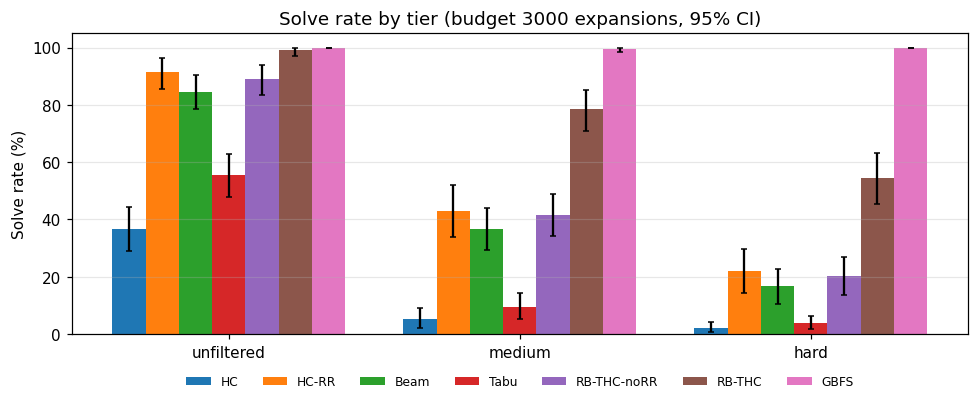

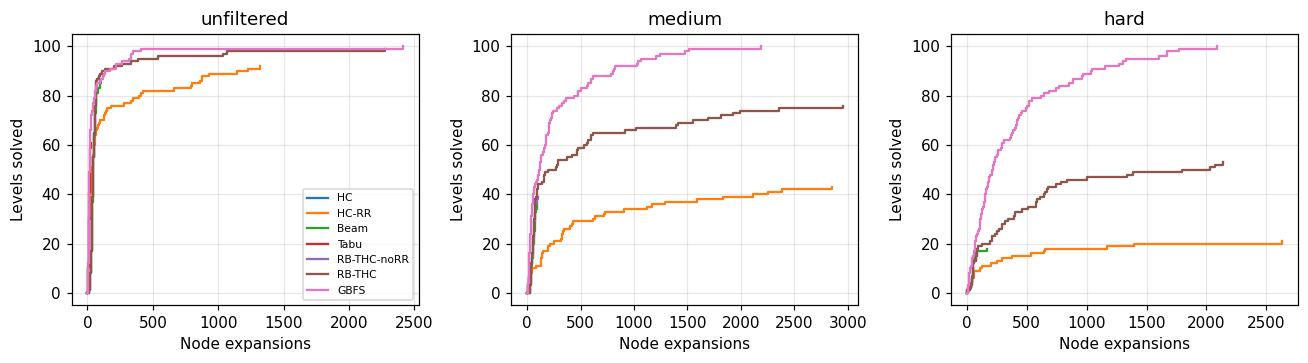

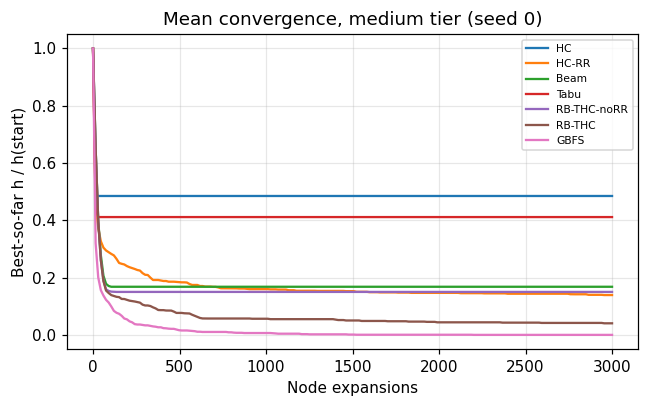

In [11]:
# CELL 11: Figures — success rate with CI; cactus plot; convergence
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 10})
tiers = list(LEVELS)
fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.8 / len(ORDER); x = np.arange(len(tiers))
for i, s in enumerate(ORDER):
    t = T1[T1.solver == s].set_index('tier').loc[tiers]
    ax.bar(x + i * w - 0.4 + w / 2, t.solve_rate, w, label=s,
           yerr=[t.solve_rate - t.ci_lo, t.ci_hi - t.solve_rate], capsize=2)
ax.set_xticks(x, tiers); ax.set_ylabel('Solve rate (%)'); ax.set_ylim(0, 105)
ax.legend(ncol=7, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False); ax.grid(axis='y', alpha=.3)
ax.set_title(f"Solve rate by tier (budget {CFG['max_expansions']} expansions, 95% CI)")
plt.tight_layout(); plt.savefig('results/fig_success.png'); plt.show()

fig, axes = plt.subplots(1, len(tiers), figsize=(4 * len(tiers), 3.4), sharey=False)
for ax, tier in zip(np.atleast_1d(axes), tiers):
    d = df[(df.tier == tier) & (df.seed == 0)]
    for s in ORDER:
        e = np.sort(d[(d.solver == s) & d.solved].expansions.values)
        ax.step(np.r_[0, e], np.arange(len(e) + 1), where='post', label=s)
    ax.set_title(tier); ax.set_xlabel('Node expansions'); ax.set_ylabel('Levels solved')
    ax.grid(alpha=.3)
np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig('results/fig_cactus.png'); plt.show()

def mean_convergence(tier, solver, grid):
    curves = []
    for lv in LEVELS[tier]:
        tr = TRACES.get((tier, lv.name, solver, CFG['beam_width'], CFG['tabu_size']))
        if not tr: continue
        e, h = np.array(tr).T
        h0 = h[0] if h[0] > 0 else 1.0
        curves.append(np.interp(grid, e, h / h0, left=1.0, right=h[-1] / h0))
    return np.mean(curves, 0)
grid = np.linspace(0, CFG['max_expansions'], 200)
fig, ax = plt.subplots(figsize=(6, 3.8))
for s in ORDER: ax.plot(grid, mean_convergence('medium', s, grid), label=s)
ax.set_xlabel('Node expansions'); ax.set_ylabel('Best-so-far h / h(start)')
ax.set_title('Mean convergence, medium tier (seed 0)'); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig('results/fig_convergence.png'); plt.show()

In [12]:
# CELL 12: Failure analysis — why runs end without a solution
F = (df[~df.solved].groupby(['tier', 'solver']).reason.value_counts(normalize=True)
     .mul(100).round(1).unstack(fill_value=0))
F.to_csv('results/table_failure_reasons.csv'); F

reason                  budget  local_optimum  no_candidates
tier       solver                                           
hard       Beam           92.1            0.0            7.9
           HC              0.0          100.0            0.0
           HC-RR         100.0            0.0            0.0
           RB-THC        100.0            0.0            0.0
           RB-THC-noRR     0.0            0.0          100.0
           Tabu            0.0            0.0          100.0
medium     Beam           93.4            0.0            6.6
           GBFS          100.0            0.0            0.0
           HC              0.0          100.0            0.0
           HC-RR         100.0            0.0            0.0
           RB-THC        100.0            0.0            0.0
           RB-THC-noRR     0.0            0.0          100.0
           Tabu            0.0            0.0          100.0
unfiltered Beam           89.6            0.0           10.4
           HC              0.0          100.0            0.0
           HC-RR         100.0            0.0            0.0
           RB-THC        100.0            0.0            0.0
           RB-THC-noRR     0.0            0.0          100.0
           Tabu            0.0            0.0          100.0

3750 sensitivity runs
  500/3750 runs, 63s
  1000/3750 runs, 116s
  1500/3750 runs, 208s
  2000/3750 runs, 272s
  2500/3750 runs, 355s
  3000/3750 runs, 389s
  3500/3750 runs, 461s


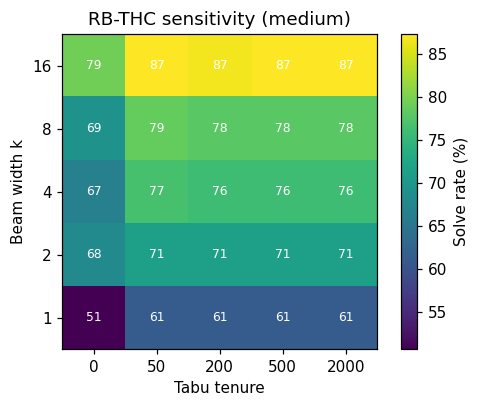

tabu,0,50,200,500,2000
k,,,,,
1,50.7,61.3,61.3,61.3,61.3
2,68.0,71.3,71.3,71.3,71.3
4,66.7,76.7,76.0,76.0,76.0
8,69.3,78.7,78.0,78.0,78.0
16,79.3,87.3,86.7,87.3,87.3


In [13]:
# CELL 13: Sensitivity — beam width k and tabu tenure (RB-THC, medium tier subset)
SUB_TIER, SUB_N, SUB_SEEDS = 'medium', 50, [0, 1, 2]
ks, tabus = [1, 2, 4, 8, 16], [0, 50, 200, 500, 2000]
sjobs = [(SUB_TIER, li, 'RB-THC', sd, P, k, tb)
         for li in range(min(SUB_N, len(LEVELS[SUB_TIER]))) for k in ks for tb in tabus for sd in SUB_SEEDS]
print(len(sjobs), 'sensitivity runs')
sdf, _ = run_grid(sjobs, CFG['n_workers'])
sdf.to_csv('results/sensitivity_runs.csv', index=False)
S = sdf.pivot_table(index='k', columns='tabu', values='solved', aggfunc='mean') * 100
S.to_csv('results/table_sensitivity.csv')
fig, ax = plt.subplots(figsize=(5, 3.8))
im = ax.imshow(S.values, cmap='viridis', origin='lower')
ax.set_xticks(range(len(tabus)), tabus); ax.set_yticks(range(len(ks)), ks)
ax.set_xlabel('Tabu tenure'); ax.set_ylabel('Beam width k')
for i in range(len(ks)):
    for j in range(len(tabus)):
        ax.text(j, i, f"{S.values[i, j]:.0f}", ha='center', va='center', color='w', fontsize=8)
plt.colorbar(im, label='Solve rate (%)'); ax.set_title(f'RB-THC sensitivity ({SUB_TIER})')
plt.tight_layout(); plt.savefig('results/fig_sensitivity.png'); plt.show()
S.round(1)

In [14]:
# CELL 14: Heuristic check — paper heuristic (nearest Manhattan) vs matching, RB-THC & HC, medium subset
P2 = dict(CFG, heuristic='nearest')
hjobs = [(SUB_TIER, li, s, sd, P2, CFG['beam_width'], CFG['tabu_size'])
         for li in range(min(SUB_N, len(LEVELS[SUB_TIER]))) for s in ['HC', 'RB-THC'] for sd in SUB_SEEDS]
hdf, _ = run_grid(hjobs, CFG['n_workers']); hdf['heuristic'] = 'nearest'
ref = df[(df.tier == SUB_TIER) & df.solver.isin(['HC', 'RB-THC']) & df.seed.isin(SUB_SEEDS)
         & df.level.isin([lv.name for lv in LEVELS[SUB_TIER][:SUB_N]])].assign(heuristic='matching')
H = pd.concat([hdf, ref]).groupby(['heuristic', 'solver']).solved.mean().mul(100).unstack()
H.to_csv('results/table_heuristic.csv'); H.round(1)

solver,HC,RB-THC
heuristic,,
matching,4.7,76.0
nearest,0.0,53.3


In [15]:
# CELL 15: Runtime / memory summary (per-expansion cost; peak states held: beam+tabu vs GBFS closed list)
R = df.assign(us_per_exp=1e6 * df.time / df.expansions.clip(lower=1)).groupby('solver') \
      [['us_per_exp', 'expansions', 'generated', 'peak_stored_states', 'time']].median()
R.to_csv('results/table_runtime.csv'); R.round(2)

,us_per_exp,expansions,generated,peak_stored_states,time
solver,,,,,
Beam,257.73,953.0,2714.5,4.0,0.21
GBFS,280.29,68.0,224.0,148.5,0.02
HC,282.43,8.0,30.0,1.0,0.00
HC-RR,246.98,1825.5,4601.0,1.0,0.26
RB-THC,280.01,95.5,442.5,67.0,0.04
RB-THC-noRR,273.99,57.0,214.0,58.0,0.02
Tabu,256.41,13.0,43.0,13.0,0.00


Theoretical RB-THC bound: k + T = 504 states



mean    50%     95%     max
tier       solver                                   
hard       Beam           4.0    4.0     4.0     4.0
           GBFS         556.2  319.5  1773.4  2407.0
           RB-THC        96.8   87.0   188.1   272.0
           RB-THC-noRR   72.9   61.0   141.0   314.0
           Tabu          13.8   13.0    24.0    48.0
medium     Beam           4.0    4.0     4.0     4.0
           GBFS         428.9  178.5  1588.1  3800.0
           RB-THC        84.5   73.0   178.0   272.0
           RB-THC-noRR   71.3   63.5   139.1   295.0
           Tabu          14.3   13.0    28.0   103.0
unfiltered Beam           4.0    4.0     4.0     4.0
           GBFS         136.5   78.0   411.3  3886.0
           RB-THC        55.3   48.0    96.0   241.0
           RB-THC-noRR   55.5   47.0    96.0   487.0
           Tabu          15.3   13.0    30.0    79.0

median            max          count       
solved                   False  True    False   True   False  True 
tier       solver                                                  
hard       Beam            4.0    4.0     4.0     4.0  417.0   83.0
           GBFS            NaN  319.5     NaN  2407.0    NaN  500.0
           RB-THC        102.5   75.0   229.0   272.0  228.0  272.0
           RB-THC-noRR    63.0   58.0   314.0   126.0  398.0  102.0
           Tabu           13.0   14.0    48.0    24.0  481.0   19.0
medium     Beam            4.0    4.0     4.0     4.0  317.0  183.0
           GBFS         3494.0  173.0  3800.0  3648.0    3.0  497.0
           RB-THC         99.0   68.0   272.0   264.0  108.0  392.0
           RB-THC-noRR    64.0   61.0   295.0   126.0  293.0  207.0
           Tabu           12.0   17.0   103.0    30.0  452.0   48.0
unfiltered Beam            4.0    4.0     4.0     4.0   77.0  423.0
           GBFS            NaN   78.0     NaN  3886.0    NaN  500.0
           RB-THC        177.0   47.0   186.0   241.0    5.0  495.0
           RB-THC-noRR    71.0   45.0   487.0   104.0   55.0  445.0
           Tabu           14.0   12.0    79.0    41.0  223.0  277.0

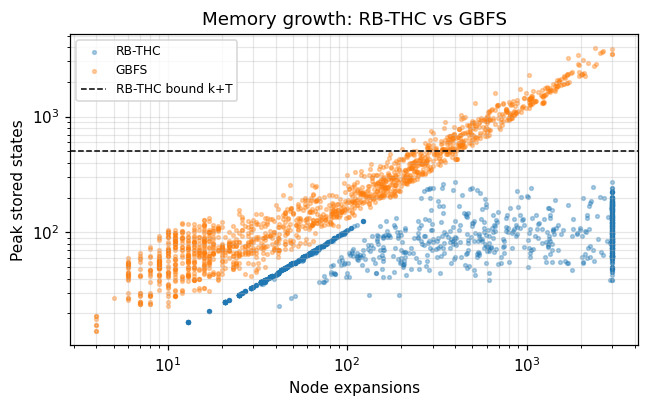

GBFS: median 2.08 stored states per expansion


In [16]:
# CELL 16: memory scaling — RB-THC (bounded: k + T) vs GBFS (closed list grows)
MEM_SOLVERS = ['RB-THC', 'RB-THC-noRR', 'Beam', 'Tabu', 'GBFS']
d = df[df.solver.isin(MEM_SOLVERS)]

# 1) Peak stored states per tier, overall and split by solved / unsolved
M = (d.groupby(['tier', 'solver']).peak_stored_states
       .describe(percentiles=[.5, .95])[['mean', '50%', '95%', 'max']])
M_split = (d.groupby(['tier', 'solver', 'solved']).peak_stored_states
             .agg(['median', 'max', 'count']).unstack('solved'))
M.to_csv('results/table_memory.csv'); M_split.to_csv('results/table_memory_by_outcome.csv')
print(f"Theoretical RB-THC bound: k + T = {CFG['beam_width'] + CFG['tabu_size']} states\n")
display(M.round(1)); display(M_split.round(1))

# 2) Growth: peak memory vs expansions used (bounded vs unbounded)
fig, ax = plt.subplots(figsize=(6, 3.8))
for s in ['RB-THC', 'GBFS']:
    x = d[d.solver == s]
    ax.scatter(x.expansions, x.peak_stored_states, s=6, alpha=.35, label=s)
ax.axhline(CFG['beam_width'] + CFG['tabu_size'], ls='--', c='k', lw=1, label='RB-THC bound k+T')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Node expansions'); ax.set_ylabel('Peak stored states')
ax.set_title('Memory growth: RB-THC vs GBFS'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('results/fig_memory.png'); plt.show()

# 3) Slope of GBFS memory vs expansions (states stored per expansion)
g = d[(d.solver == 'GBFS') & (d.expansions > 0)]
print(f"GBFS: median {np.median(g.peak_stored_states / g.expansions):.2f} stored states per expansion")

In [17]:
# CELL 17: fair-memory check — GBFS with the SAME memory cap as RB-THC (k + T states)
def gbfs_capped(lv, rng, P, cap):
    """GBFS whose open + closed lists together never exceed `cap` entries
       (conservative: open entries are also counted in closed until evicted).
       Closed = FIFO (oldest forgotten); open trimmed to its best entries."""
    ctr = Counter(P['max_expansions'], P['time_limit']); hk = P['heuristic']
    cap_c = cap // 2; cap_o = cap - cap_c
    s0 = canon(lv, lv.player0, lv.boxes0); h0 = heuristic(lv, s0[1], hk)
    openl = [(h0, rng.random(), (s0, None))]
    closed = collections.deque([s0]); cset = {s0}
    best_node, best_h, trace = (s0, None), h0, []
    while openl and not ctr.out():
        h, _, nd = heapq.heappop(openl)
        if is_goal(lv, nd[0]): return _result(lv, True, nd, 0.0, ctr, 'solved', trace)
        if h < best_h: best_h, best_node = h, nd
        for s in successors(lv, nd[0], ctr):
            if s in cset: continue
            closed.append(s); cset.add(s)
            if len(closed) > cap_c: cset.discard(closed.popleft())
            heapq.heappush(openl, (heuristic(lv, s[1], hk), rng.random(), (s, nd)))
        if len(openl) > cap_o:
            openl = heapq.nsmallest(cap_o, openl); heapq.heapify(openl)
        ctr.mem = max(ctr.mem, len(openl) + len(closed))
        trace.append((ctr.exp, best_h))
    return _result(lv, False, best_node, best_h, ctr, 'budget' if openl else 'exhausted', trace)

if '_BASE_MAKE' not in globals(): _BASE_MAKE = make_solvers   # safe to re-run this cell
def make_solvers(P, k=None, tabu=None):
    s = _BASE_MAKE(P, k, tabu)
    cap = (k or P['beam_width']) + (P['tabu_size'] if tabu is None else tabu)
    s['GBFS-cap'] = (lambda lv, rng: gbfs_capped(lv, rng, P, cap), True)
    return s

cjobs = [(t, li, 'GBFS-cap', sd, P, P['beam_width'], P['tabu_size'])
         for t in LEVELS for li in range(len(LEVELS[t])) for sd in CFG['seeds']]
print(len(cjobs), 'runs')
cdf, _ = run_grid(cjobs, CFG['n_workers'])
assert cdf.loc[cdf.solved, 'verified'].all()
cdf.to_csv('results/gbfs_capped_runs.csv', index=False)

both = pd.concat([df[df.solver.isin(['RB-THC', 'GBFS'])], cdf])
C = both.groupby(['tier', 'solver']).agg(solve_rate=('solved', 'mean'),
                                         peak_mem_max=('peak_stored_states', 'max'))
C['solve_rate'] *= 100
cmp_rows = []
for tier in LEVELS:
    s0 = both[(both.tier == tier) & (both.seed == 0)].pivot_table(
        index='level', columns='solver', values='solved', aggfunc='first').astype(bool)
    a, b = s0['RB-THC'], s0['GBFS-cap']
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    cmp_rows.append(dict(tier=tier, rbthc_only=n10, gbfs_cap_only=n01,
                         p_mcnemar=binomtest(n10, n10 + n01, .5).pvalue if n10 + n01 else 1.0))
C.to_csv('results/table_gbfs_capped.csv')
display(C.round(1)); display(pd.DataFrame(cmp_rows).round(4))

1500 runs
  500/1500 runs, 21s
  1000/1500 runs, 75s
  1500/1500 runs, 167s


solve_rate  peak_mem_max
tier       solver                            
hard       GBFS           100.0          2407
           GBFS-cap        68.0           504
           RB-THC          54.4           272
medium     GBFS            99.4          3800
           GBFS-cap        82.4           504
           RB-THC          78.4           272
unfiltered GBFS           100.0          3886
           GBFS-cap        96.4           504
           RB-THC          99.0           241

,tier,rbthc_only,gbfs_cap_only,p_mcnemar
0,unfiltered,5,1,0.2188
1,medium,9,15,0.3075
2,hard,8,22,0.0161


In [18]:
!zip -r results.zip results
from google.colab import files; files.download('results.zip')

  adding: results/ (stored 0%)
  adding: results/table_stats.csv (deflated 54%)
  adding: results/table_heuristic.csv (deflated 25%)
  adding: results/table_gbfs_capped.csv (deflated 47%)
  adding: results/fig_cactus.png (deflated 16%)
  adding: results/sensitivity_runs.csv (deflated 81%)
  adding: results/fig_memory.png (deflated 4%)
  adding: results/table_memory.csv (deflated 57%)
  adding: results/config.json (deflated 52%)
  adding: results/fig_success.png (deflated 23%)
  adding: results/table_failure_reasons.csv (deflated 67%)
  adding: results/fig_convergence.png (deflated 13%)
  adding: results/table_cost_common.csv (deflated 62%)
  adding: results/main_runs.csv (deflated 79%)
  adding: results/table_runtime.csv (deflated 38%)
  adding: results/fig_sensitivity.png (deflated 15%)
  adding: results/table_main.csv (deflated 59%)
  adding: results/table_memory_by_outcome.csv (deflated 59%)
  adding: results/gbfs_capped_runs.csv (deflated 78%)
  adding: results/table_sensitivity.cs

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>